<a href="https://colab.research.google.com/github/radengustirangga-hub/Tugas_Preprocessing_data/blob/main/Preprocessing_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Individu: Preprocessing Data
## Preprocessing Breast Cancer Wisconsin (Diagnostic) Dataset

**Nama:** Raden Gusti Rangga  
**NIM:** 2404010013  
**Mata Kuliah:** Data Mining

## 1. Latar Belakang

Data di dunia nyata jarang langsung siap dipakai. Data bisa memiliki nilai kosong, duplikat, tipe data yang salah, outlier, skala fitur yang berbeda-beda, atau kolom yang tidak informatif. Jika data seperti itu langsung dimasukkan ke algoritma *machine learning*, hasilnya bisa menyesatkan.

**Preprocessing** adalah rangkaian proses membersihkan dan mengubah data mentah menjadi data yang siap dianalisis atau dimodelkan.

**Tujuan tugas ini:**
1. Mengambil data riil langsung dari sumber aslinya (UCI Machine Learning Repository).
2. Melakukan tahapan preprocessing secara berurutan dan terdokumentasi.
3. Menunjukkan kondisi data sebelum dan sesudah preprocessing.
4. Menguji secara sederhana apakah hasil preprocessing layak dipakai untuk klasifikasi.

## 2. Dataset

Dataset: **Breast Cancer Wisconsin (Diagnostic) / WDBC**, disumbangkan pada tahun 1995 oleh Wolberg, Street, dan Mangasarian (University of Wisconsin).

| Aspek | Keterangan |
|---|---|
| Sumber | UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic |
| File | `wdbc.data` (data mentah, tanpa baris header) |
| Jumlah data | 569 sampel pasien |
| Kolom | `ID`, `Diagnosis` (M = malignant/ganas, B = benign/jinak), dan 30 fitur numerik |
| Asal fitur | Citra digital *fine needle aspirate* (FNA) massa payudara; ciri inti sel |
| Struktur fitur | 10 karakteristik (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension) × 3 nilai (mean, standard error, worst) |

File mentah dari UCI **tidak memiliki nama kolom**, sehingga nama kolom harus dipasang sendiri berdasarkan dokumentasi dataset.

### Ringkasan Tahapan Preprocessing

| No | Tahap | Tujuan |
|---|---|---|
| 1 | Load data mentah | Mengambil data asli dan menyimpan salinan mentah |
| 2 | Pemeriksaan awal | Mengenali kondisi data sebelum diolah |
| 3 | Data cleaning | Duplikat, kolom ID, validasi nilai |
| 4 | Encoding target | Mengubah label `M`/`B` menjadi angka |
| 5 | Missing value | Memastikan tidak ada data kosong |
| 6 | Pembagian data | Memisahkan data latih dan uji (mencegah *data leakage*) |
| 7 | Outlier | Mendeteksi dan menangani nilai ekstrem |
| 8 | Skewness | Mengurangi kemiringan distribusi dengan transformasi log |
| 9 | Seleksi fitur | Membuang fitur yang berkorelasi sangat tinggi |
| 10 | Scaling | Menyamakan skala fitur |
| 11 | PCA (opsional) | Reduksi dimensi |
| 12 | Penyeimbangan kelas (opsional) | Menyeimbangkan jumlah kelas pada data latih |
| 13 | Validasi | Membandingkan hasil sebelum dan sesudah preprocessing |
| 14 | Penyimpanan hasil | Menyimpan data olahan |

## 3. Tahapan Penerapan

### 3.1 Load Data Mentah

Data dibaca langsung dari server UCI. Jika unduhan otomatis gagal (misalnya tidak ada koneksi atau URL berubah), unduh `wdbc.data` dari halaman UCI (tombol *Download* → ZIP, ekstrak), lalu unggah ke Colab (ikon folder → Upload) dan jalankan ulang sel ini.

Karena file asli tidak memiliki header, nama kolom dipasang manual lewat parameter `names`.

In [ ]:
import os
import socket
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
socket.setdefaulttimeout(20)

# Nama kolom sesuai dokumentasi WDBC: ID, Diagnosis, lalu 10 fitur x (mean, se, worst)
nama_dasar = ["radius", "texture", "perimeter", "area", "smoothness",
              "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
kolom = ["id", "diagnosis"] + [f"{n}_{s}" for s in ("mean", "se", "worst") for n in nama_dasar]

URL_UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

try:
    df_raw = pd.read_csv(URL_UCI, header=None, names=kolom)
    print("Data diunduh langsung dari UCI.")
except Exception as e:
    print("Unduh langsung gagal:", type(e).__name__)
    if not os.path.exists("wdbc.data"):
        raise FileNotFoundError("Unduh wdbc.data dari halaman UCI, unggah ke Colab, lalu jalankan ulang sel ini.")
    df_raw = pd.read_csv("wdbc.data", header=None, names=kolom)
    print("Data dibaca dari file lokal wdbc.data.")

# simpan salinan data mentah (untuk repository GitHub)
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
df_raw.to_csv("data/raw/wdbc_raw.csv", index=False)

df = df_raw.copy()
print("Ukuran data (baris, kolom):", df.shape)
df.head()

Data diunduh langsung dari UCI.
Ukuran data (baris, kolom): (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### 3.2 Pemeriksaan Awal (Data Mentah)

In [ ]:
df.info()
display(df.describe().T.head(10))

print("Missing value total :", int(df.isnull().sum().sum()))
print("Baris duplikat      :", int(df.duplicated().sum()))
print("ID duplikat         :", int(df["id"].duplicated().sum()))
print()
print(df["diagnosis"].value_counts())
print((df["diagnosis"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.00000,869218.00000,906024.00000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.98100,11.70000,13.37000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.71000,16.17000,18.84000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.79000,75.17000,86.24000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.50000,420.30000,551.10000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.05263,0.08637,0.09587,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.01938,0.06492,0.09263,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.00000,0.02956,0.06154,1.307000e-01,4.268000e-01
concave_points_mean,569.0,4.891915e-02,3.880284e-02,0.00000,0.02031,0.03350,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.10600,0.16190,0.17920,1.957000e-01,3.040000e-01


Missing value total : 0
Baris duplikat      : 0
ID duplikat         : 0

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.7 %
M    37.3 %
Name: proportion, dtype: object


**Catatan:** kondisi awal inilah yang menjadi pembanding di akhir tugas. Perhatikan tipe data tiap kolom (`diagnosis` bertipe teks, sisanya angka), ada tidaknya nilai kosong dan duplikat, serta perbandingan jumlah kelas.

### 3.3 Data Cleaning

- Kolom `id` hanyalah nomor identitas pasien. Tidak membawa informasi untuk membedakan tumor jinak/ganas, bahkan bisa menyesatkan model jika ikut dipakai sebagai fitur, sehingga **dibuang**.
- Label `diagnosis` dirapikan (spasi/huruf besar-kecil) dan divalidasi hanya berisi `M` dan `B`.
- Duplikat diperiksa **tanpa** kolom `id` (karena `id` selalu unik).
- Nilai fitur divalidasi: tidak boleh negatif, harus numerik. Nilai `0` diperiksa karena bisa saja berupa kode data hilang yang "menyamar".

In [ ]:
# Rapikan dan validasi label
df["diagnosis"] = df["diagnosis"].astype(str).str.strip().str.upper()
print("Nilai unik diagnosis:", df["diagnosis"].unique())

# Buang kolom identitas
df = df.drop(columns="id")

# Duplikat (tanpa id)
n0 = len(df)
df = df.drop_duplicates()
print("Baris dihapus karena duplikat:", n0 - len(df))

# Validasi nilai fitur
fitur = [c for c in df.columns if c != "diagnosis"]
print("Nilai negatif       :", int((df[fitur] < 0).sum().sum()))
print("Kolom non-numerik   :", [c for c in fitur if not pd.api.types.is_numeric_dtype(df[c])])

# Cek nilai nol (bisa valid, bisa kode data hilang)
nol = (df[fitur] == 0).sum()
print("\nKolom yang berisi nilai 0:")
display(nol[nol > 0])

Nilai unik diagnosis: ['M' 'B']
Baris dihapus karena duplikat: 0
Nilai negatif       : 0
Kolom non-numerik   : []

Kolom yang berisi nilai 0:


,0
concavity_mean,13
concave_points_mean,13
concavity_se,13
concave_points_se,13
concavity_worst,13
concave_points_worst,13


**Interpretasi nilai 0:** pada `concavity` dan `concave_points`, nilai 0 berarti inti sel berbentuk sangat halus tanpa lekukan. Ini **nilai yang sah**, bukan data hilang, sehingga tidak diubah. Fitur lain (radius, area, dll.) tidak mungkin bernilai 0 secara fisik dan memang tidak ada yang bernilai 0.

### 3.4 Encoding Target

Label teks diubah menjadi angka: **`M` (malignant/ganas) = 1** dan **`B` (benign/jinak) = 0**

### 3.5 Penanganan Missing Value

Dokumentasi UCI menyatakan dataset ini tidak memiliki nilai kosong. Tetap dilakukan pengecekan sebagai prosedur standar; jika ada, nilai numerik akan diisi **median** (tahan terhadap outlier).

In [ ]:
print("Missing sebelum:", int(df[fitur].isnull().sum().sum()))
df[fitur] = df[fitur].fillna(df[fitur].median())
print("Missing sesudah:", int(df[fitur].isnull().sum().sum()))

Missing sebelum: 0
Missing sesudah: 0


### 3.6 Pembagian Data Latih dan Data Uji

Data dibagi **sebelum** tahap yang "belajar" dari data (batas outlier, transformasi, seleksi fitur, scaling). Jika tidak, informasi dari data uji ikut "bocor" ke proses latih (*data leakage*) dan hasil evaluasi menjadi terlalu optimistis.

Pembagian 80% latih dan 20% uji dengan `stratify=y` agar proporsi kelas tetap sama.

In [ ]:
from sklearn.model_selection import train_test_split

# Memastikan kolom 'target' sudah dibuat jika sel c012 belum dieksekusi secara berurutan
if "target" not in df.columns and "diagnosis" in df.columns:
    df["target"] = df["diagnosis"].map({"B": 0, "M": 1})
    df = df.drop(columns="diagnosis")

X = df[fitur]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

X_train_awal = X_train.copy()   # simpan untuk perbandingan di tahap validasi
X_test_awal = X_test.copy()

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi ganas (latih):", round(y_train.mean(), 3), "| (uji):", round(y_test.mean(), 3))

Data latih: (455, 30) | Data uji: (114, 30)
Proporsi ganas (latih): 0.374 | (uji): 0.368


### 3.7 Penanganan Outlier

Outlier dideteksi dengan metode **IQR** (nilai di luar Q1 − 1.5·IQR dan Q3 + 1.5·IQR). Batas dihitung **hanya dari data latih**.

Pada data medis, nilai ekstrem sering kali **valid** (misalnya tumor yang memang besar). Menghapus barisnya akan membuang pasien penting dan memperkecil data yang hanya 569 baris. Karena itu outlier **tidak dihapus**, melainkan dibatasi nilainya pada batas IQR (*winsorizing*).

Total nilai outlier pada data latih: 494
Fitur dengan outlier terbanyak:


,0
area_se,53
perimeter_se,34
radius_se,31
compactness_se,24
concavity_se,24
fractal_dimension_se,23
symmetry_se,22
area_worst,21
smoothness_se,20
symmetry_worst,20


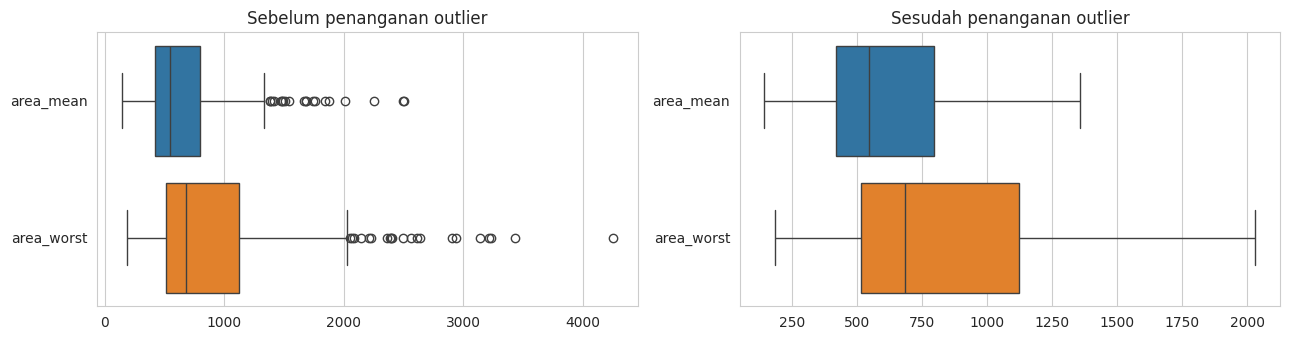

In [ ]:
Q1, Q3 = X_train.quantile(0.25), X_train.quantile(0.75)
IQR = Q3 - Q1
bawah, atas = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

jumlah_outlier = ((X_train < bawah) | (X_train > atas)).sum().sort_values(ascending=False)
print("Total nilai outlier pada data latih:", int(jumlah_outlier.sum()))
print("Fitur dengan outlier terbanyak:")
display(jumlah_outlier.head(10))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
sns.boxplot(data=X_train[["area_mean", "area_worst"]], orient="h", ax=ax[0])
ax[0].set_title("Sebelum penanganan outlier")

TERAPKAN_CAPPING = True
if TERAPKAN_CAPPING:
    X_train = X_train.clip(lower=bawah, upper=atas, axis=1)
    X_test = X_test.clip(lower=bawah, upper=atas, axis=1)

sns.boxplot(data=X_train[["area_mean", "area_worst"]], orient="h", ax=ax[1])
ax[1].set_title("Sesudah penanganan outlier")
plt.tight_layout(); plt.show()

### 3.8 Skewness dan Transformasi Log

Distribusi yang sangat miring (|skewness| > 1) dapat mengganggu model berbasis jarak/linear. Fitur yang miring ditransformasi dengan `log1p` (aman untuk nilai 0).

In [ ]:
skew_sebelum = X_train.skew()
kolom_miring = skew_sebelum[skew_sebelum.abs() > 1].index.tolist()
print("Fitur sangat miring (|skew| > 1):", kolom_miring)

X_train[kolom_miring] = np.log1p(X_train[kolom_miring])
X_test[kolom_miring] = np.log1p(X_test[kolom_miring])

if kolom_miring:
    perbandingan = pd.DataFrame({"skew sebelum": skew_sebelum[kolom_miring],
                                 "skew sesudah": X_train[kolom_miring].skew()}).round(3)
    display(perbandingan)
else:
    print("Tidak ada fitur yang perlu ditransformasi setelah penanganan outlier.")

Fitur sangat miring (|skew| > 1): ['concavity_mean', 'concave_points_mean', 'radius_se', 'perimeter_se', 'area_se', 'area_worst']


,skew sebelum,skew sesudah
concavity_mean,1.061,0.949
concave_points_mean,1.021,0.955
radius_se,1.029,0.818
perimeter_se,1.041,0.470
area_se,1.114,0.359
area_worst,1.087,0.273


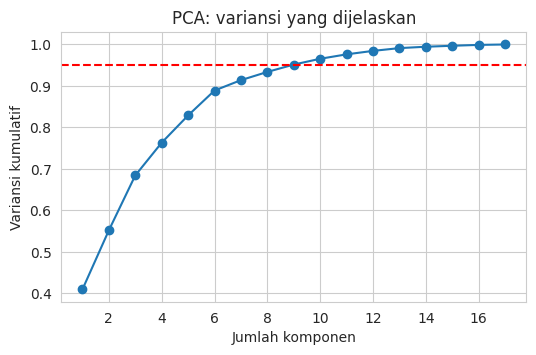

17 fitur diringkas menjadi 9 komponen (95% variansi)


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Memastikan X_train_s dan X_test_s sudah didefinisikan
if 'X_train_s' not in globals() or 'X_test_s' not in globals():
    scaler = StandardScaler().fit(X_train)
    X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
    X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

pca_penuh = PCA().fit(X_train_s)
kumulatif = np.cumsum(pca_penuh.explained_variance_ratio_)

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(kumulatif) + 1), kumulatif, marker="o")
plt.axhline(0.95, color="r", linestyle="--")
plt.xlabel("Jumlah komponen"); plt.ylabel("Variansi kumulatif")
plt.title("PCA: variansi yang dijelaskan"); plt.show()

pca = PCA(n_components=0.95).fit(X_train_s)
X_train_pca = pca.transform(X_train_s)
X_test_pca = pca.transform(X_test_s)
print(f"{X_train_s.shape[1]} fitur diringkas menjadi {pca.n_components_} komponen (95% variansi)")

### 3.9 Seleksi Fitur: Fitur Berkorelasi Tinggi

Beberapa fitur mengukur hal yang hampir sama (misalnya `radius`, `perimeter`, dan `area` yang saling berbanding lurus). Fitur yang berkorelasi sangat tinggi bersifat **redundan** dan menimbulkan multikolinearitas. Untuk setiap pasangan dengan korelasi mutlak > 0,9, salah satunya dibuang. Korelasi dihitung dari data latih.

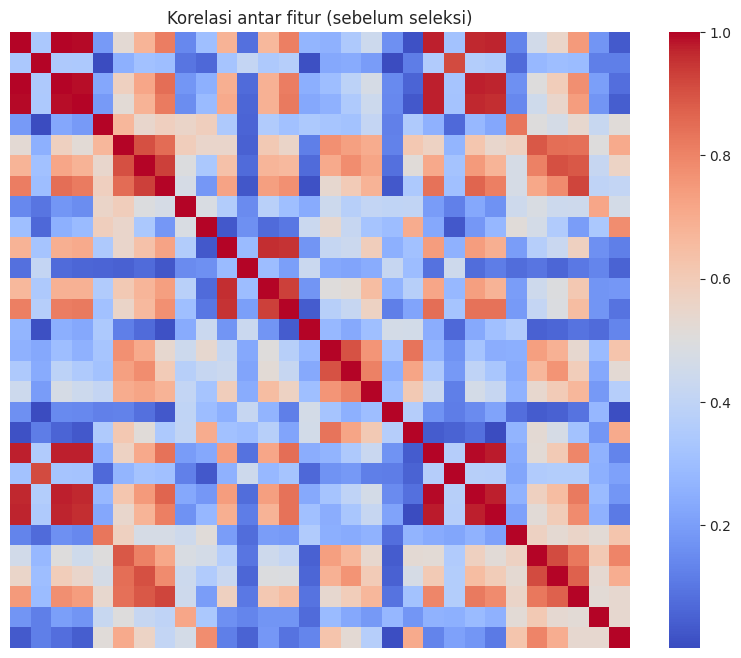

Fitur dibuang (korelasi > 0.9): 13
['perimeter_mean', 'area_mean', 'concavity_mean', 'concave_points_mean', 'perimeter_se', 'area_se', 'concavity_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'concavity_worst', 'concave_points_worst']
Fitur tersisa: 17


In [ ]:
corr = X_train.corr().abs()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", xticklabels=False, yticklabels=False)
plt.title("Korelasi antar fitur (sebelum seleksi)")
plt.show()

segitiga = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
kolom_korelasi = [c for c in segitiga.columns if (segitiga[c] > 0.9).any()]

X_train = X_train.drop(columns=kolom_korelasi)
X_test = X_test.drop(columns=kolom_korelasi)

print(f"Fitur dibuang (korelasi > 0.9): {len(kolom_korelasi)}")
print(kolom_korelasi)
print(f"Fitur tersisa: {X_train.shape[1]}")

In [ ]:
if "target" not in df.columns and "diagnosis" in df.columns:
    df["target"] = df["diagnosis"].map({"B": 0, "M": 1})
    assert df["target"].notnull().all(), "Ada label yang tidak dikenali!"
    print(df[["diagnosis", "target"]].value_counts())
    df = df.drop(columns="diagnosis")
elif "target" in df.columns:
    print("Kolom 'target' sudah dibuat sebelumnya. Distribusi target:")
    print(df["target"].value_counts())
else:
    print("Kolom 'diagnosis' maupun 'target' tidak ditemukan!")

df.head()

Kolom 'target' sudah dibuat sebelumnya. Distribusi target:
target
0    357
1    212
Name: count, dtype: int64


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


### 3.10 Scaling (Standardisasi)

Fitur memiliki skala yang sangat berbeda (`area` ratusan, `smoothness` di bawah 1). `StandardScaler` mengubah tiap fitur menjadi rata-rata 0 dan simpangan baku 1. *Scaler* hanya di-*fit* pada data latih, lalu diterapkan ke data uji.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

cek = pd.DataFrame({"mean latih": X_train_s.mean(), "std latih": X_train_s.std(),
                    "mean uji": X_test_s.mean(), "std uji": X_test_s.std()}).round(3)
display(cek.head(8))

,mean latih,std latih,mean uji,std uji
radius_mean,-0.0,1.001,-0.039,0.973
texture_mean,0.0,1.001,-0.151,1.022
smoothness_mean,0.0,1.001,0.143,0.930
compactness_mean,0.0,1.001,0.075,0.965
symmetry_mean,-0.0,1.001,-0.058,0.981
fractal_dimension_mean,-0.0,1.001,0.039,0.992
radius_se,0.0,1.001,-0.067,0.949
texture_se,0.0,1.001,0.009,1.097


**Catatan:** rata-rata data latih = 0 dan std = 1, sedangkan data uji hanya mendekati. Ini wajar dan benar, karena data uji memakai statistik dari data latih.

### 3.11 PCA (Opsional)

*Principal Component Analysis* meringkas fitur menjadi komponen yang saling tidak berkorelasi. Dipilih jumlah komponen yang menjelaskan 95% variansi.

### 3.12 Penyeimbangan Kelas (Opsional)

Kelas ganas lebih sedikit dari jinak. Perbedaannya tergolong ringan, namun sebagai latihan dilakukan *random oversampling* pada kelas minoritas. Ini **hanya dilakukan pada data latih**; data uji dibiarkan apa adanya agar evaluasinya jujur.

In [ ]:
from sklearn.utils import resample

train = X_train_s.assign(target=y_train)
mayoritas = train[train["target"] == 0]   # jinak
minoritas = train[train["target"] == 1]   # ganas

minoritas_up = resample(minoritas, replace=True, n_samples=len(mayoritas), random_state=42)
train_seimbang = pd.concat([mayoritas, minoritas_up]).sample(frac=1, random_state=42)

print("Kelas latih sebelum :", y_train.value_counts().to_dict())
print("Kelas latih sesudah :", train_seimbang["target"].value_counts().to_dict())

Kelas latih sebelum : {0: 285, 1: 170}
Kelas latih sesudah : {1: 285, 0: 285}


### 3.13 Validasi: Sebelum vs Sesudah Preprocessing

Untuk melihat apakah preprocessing merusak atau memperbaiki data, dilatih model sederhana (*Logistic Regression*) pada beberapa versi data, lalu diuji pada data uji yang sama.

Metrik *recall* dihitung untuk kelas **ganas**, karena kesalahan terburuk adalah tumor ganas yang dianggap jinak.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, f1_score

def evaluasi(Xtr, ytr, Xte, yte):
    model = LogisticRegression(max_iter=5000, random_state=42).fit(Xtr, ytr)
    p = model.predict(Xte)
    return [accuracy_score(yte, p), recall_score(yte, p, pos_label=1), f1_score(yte, p, pos_label=1)]

hasil = pd.DataFrame({
    "Tanpa preprocessing":                evaluasi(X_train_awal, y_train, X_test_awal, y_test),
    "Dengan preprocessing":               evaluasi(X_train_s, y_train, X_test_s, y_test),
    "Preprocessing + oversampling":       evaluasi(train_seimbang.drop(columns="target"), train_seimbang["target"], X_test_s, y_test),
    "Preprocessing + PCA":                evaluasi(X_train_pca, y_train, X_test_pca, y_test),
}, index=["Akurasi", "Recall (ganas)", "F1 (ganas)"]).T.round(4)
hasil

,Akurasi,Recall (ganas),F1 (ganas)
Tanpa preprocessing,0.9386,0.8571,0.9114
Dengan preprocessing,0.9737,0.9286,0.9630
Preprocessing + oversampling,0.9737,0.9286,0.9630
Preprocessing + PCA,0.9561,0.9048,0.9383


### 3.14 Ringkasan Sebelum vs Sesudah dan Penyimpanan Hasil

In [ ]:
ringkasan = pd.DataFrame({
    "Sebelum (mentah)": [df_raw.shape[0], df_raw.shape[1], int(df_raw.isnull().sum().sum()),
                         int(df_raw.drop(columns="id").duplicated().sum()), "teks (M/B)"],
    "Sesudah (olahan)": [len(X_train_s) + len(X_test_s), X_train_s.shape[1] + 1,
                         int(X_train_s.isnull().sum().sum() + X_test_s.isnull().sum().sum()),
                         int(X_train_s.duplicated().sum()), "angka (0/1)"],
}, index=["Jumlah baris", "Jumlah kolom", "Missing value", "Duplikat", "Tipe label"])
display(ringkasan)

X_train_s.assign(target=y_train).to_csv("data/processed/train_processed.csv", index=False)
X_test_s.assign(target=y_test).to_csv("data/processed/test_processed.csv", index=False)
train_seimbang.to_csv("data/processed/train_seimbang.csv", index=False)
print("Tersimpan di folder data/processed/")

# untuk mengunduh ke laptop (opsional):
# !zip -r data.zip data
# from google.colab import files; files.download("data.zip")

,Sebelum (mentah),Sesudah (olahan)
Jumlah baris,569,569
Jumlah kolom,32,18
Missing value,0,0
Duplikat,0,0
Tipe label,teks (M/B),angka (0/1)


Tersimpan di folder data/processed/


## 4. Hasil dan Pembahasan

Tuliskan pembahasan Anda berdasarkan output di atas. Poin yang bisa dibahas:

1. **Kondisi data awal:** data sudah cukup bersih (tanpa missing value dan duplikat), tetapi file mentah tidak punya nama kolom, memuat kolom `id` yang tidak informatif, dan label berupa teks.
2. **Outlier:** sebutkan fitur dengan outlier terbanyak dan alasan outlier tidak dihapus (nilai ekstrem pada data medis umumnya valid).
3. **Skewness dan korelasi:** sebutkan fitur yang ditransformasi dan fitur yang dibuang karena redundan, serta jumlah fitur sebelum dan sesudah.
4. **Dampak preprocessing:** bandingkan tabel validasi (tahap 3.13) dan jelaskan bahwa hasilnya masih berupa satu kali split.
5. **Keterbatasan:** data hanya 569 sampel dari satu sumber; keputusan seperti batas korelasi 0,9 dan batas skewness 1 bersifat pilihan dan dapat diubah.

## 5. Kesimpulan

Tuliskan kesimpulan Anda di sini, misalnya: data WDBC dari UCI telah melalui tahapan cleaning, encoding, penanganan outlier, transformasi, seleksi fitur, dan scaling sehingga menghasilkan data latih dan data uji yang siap dipakai untuk klasifikasi, dengan jumlah fitur berkurang dari 30 menjadi ... .

## 6. Referensi

1. Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1995). *Breast Cancer Wisconsin (Diagnostic)* [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic
2. Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). Nuclear feature extraction for breast tumor diagnosis. *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, 1905, 861–870.
3. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.